# Module project: build a machine-failure detector

This notebook builds the whole project, file by file, exactly as the lesson does. Run it from top to bottom in Google Colab or Jupyter: each `%%writefile` cell writes one file of the project, and each `!python` cell runs it. Then try the ideas under **Make it yours**.

Better still: type the files yourself in your own editor, and use this notebook to check your work.

## Attachments and data

- **Notebook**: `project-4-failure-detector.ipynb`, attached to this lesson and saved on your device with the course. It builds and runs the whole project. Open it in one click in Google Colab (free, nothing to install): [Open in Colab](https://colab.research.google.com/github/mahmoudyosrimahmoud13/inpace-library/blob/main/courses/bishop-dl-1-foundations/files/project-4-failure-detector.ipynb). Or open the saved copy on your device with Jupyter or VS Code.
- **Finished code**: the `projects/failure-detector` folder in the course files, to check your work.
- **Data**: Numenta Anomaly Benchmark: machine temperature, with failure labels. Source: [https://github.com/numenta/NAB/blob/master/data/realKnownCause/machine_temperature_system_failure.csv](https://github.com/numenta/NAB/blob/master/data/realKnownCause/machine_temperature_system_failure.csv) · about: [https://github.com/numenta/NAB](https://github.com/numenta/NAB) · licence: see the NAB repository (AGPL-3.0 code, data for research use). `data.py` downloads it the first time you run it and keeps it in `data/`: `combined_windows.json`, `machine_temperature.csv`, 730 KB.

In [ ]:
%pip install -q torch pandas matplotlib

Factories, servers and aircraft engines all have sensors, and the expensive question is always the same: **is something
going wrong right now?** Usually there are almost no examples of failures to learn from, but plenty of normal
operation. Density estimation turns that into a method: learn `p(x)` for normal behaviour, and raise an alarm when a new
reading is too unlikely.

In this project you build that detector with chapter 3's models, in PyTorch, on real sensor data from an industrial
machine that failed several times. The notebook attached above builds and runs the whole project; the reference code is
in the course files under `projects/failure-detector`.





## What you'll build

```mermaid
flowchart LR
    A[machine temperature<br/>every 5 min, 11 weeks] --> B[data.py<br/>one point per hour:<br/>temperature + change]
    B --> C[models.py<br/>Gaussian, independent,<br/>kernel density]
    C --> D[detect.py<br/>fit on normal weeks,<br/>alarm if p x is too low]
    D --> E[score against<br/>4 labelled failures]
```

The data comes from the Numenta Anomaly Benchmark, a public collection of real sensor streams. Engineers labelled four
periods around known failures of this machine. The detector never sees those labels: they're only used at the end, to
score it.

## Set up the project

```bash
mkdir failure-detector && cd failure-detector
python -m venv .venv && source .venv/bin/activate
pip install torch pandas matplotlib
git init
```

```text
failure-detector/
    .gitignore
    README.md
    data.py
    detect.py
    models.py
    requirements.txt
```

In [ ]:
%%writefile requirements.txt
torch
pandas
matplotlib

Writing requirements.txt


In [ ]:
%%writefile .gitignore
data/
outputs/*
!outputs/*.png
__pycache__/
.venv/

Writing .gitignore


## Step 1: from readings to points

Raw readings every 5 minutes are noisy, so we average them per hour, and describe each hour by two numbers: the mean
temperature, and how much it changed since the previous hour. A slow drift and a sudden drop to the same temperature then
look different.

The model learns from 33 days (December 18 to January 20) that contain no labelled failure.

In [ ]:
%%writefile data.py
"""Temperature of a large industrial machine, every 5 minutes for 11 weeks (Numenta Anomaly Benchmark).
Engineers labelled four periods around known failures. We turn the readings into one point per hour."""
from pathlib import Path
from urllib.request import urlopen
import json
import pandas as pd
import torch

BASE = "https://raw.githubusercontent.com/numenta/NAB/master/"
FILE = "realKnownCause/machine_temperature_system_failure.csv"
CACHE = Path("data/machine_temperature.csv")
LABELS = Path("data/combined_windows.json")
TRAIN = ("2013-12-18", "2014-01-20")          # 33 days with no labelled failure: what "normal" looks like


def load_readings():
    if not CACHE.exists():
        CACHE.parent.mkdir(exist_ok=True)
        CACHE.write_bytes(urlopen(BASE + "data/" + FILE).read())
    return pd.read_csv(CACHE, parse_dates=["timestamp"]).set_index("timestamp")["value"]


def failure_windows():
    if not LABELS.exists():
        LABELS.parent.mkdir(exist_ok=True)
        LABELS.write_bytes(urlopen(BASE + "labels/combined_windows.json").read())
    labels = json.loads(LABELS.read_text())[FILE]
    return [(pd.Timestamp(a), pd.Timestamp(b)) for a, b in labels]


def hourly_features():
    """Each hour -> (mean temperature, change since the previous hour)."""
    hourly = load_readings().resample("1h").mean().dropna()
    table = pd.DataFrame({"temp": hourly, "change": hourly.diff()}).dropna()
    return table


if __name__ == "__main__":
    table = hourly_features()
    print(f"{len(table)} hours from {table.index[0]:%Y-%m-%d} to {table.index[-1]:%Y-%m-%d}")
    train = table.loc[TRAIN[0]:TRAIN[1]]
    print(f"training hours (normal operation): {len(train)}")
    print(train.describe().loc[["mean", "std", "min", "max"]].round(2))
    for a, b in failure_windows():
        print(f"labelled failure window: {a:%Y-%m-%d %H:%M} to {b:%Y-%m-%d %H:%M}")

Writing data.py


In [ ]:
!python data.py

1890 hours from 2013-12-02 to 2014-02-19
training hours (normal operation): 816
        temp  change
mean   89.44   -0.01
std     7.79    2.85
min    53.30  -14.03
max   106.30   18.60
labelled failure window: 2013-12-10 06:25 to 2013-12-12 05:35
labelled failure window: 2013-12-15 17:50 to 2013-12-17 17:00
labelled failure window: 2014-01-27 14:20 to 2014-01-29 13:30
labelled failure window: 2014-02-07 14:55 to 2014-02-09 14:05


## Step 2: three density models

All three come from chapter 3, and all three answer the same question: `log p(x)` for a new hour.

- **Full Gaussian** (section 3.2.7): the maximum-likelihood mean and covariance. One peak, elliptical contours.
- **Independent Gaussian**: the same with a diagonal covariance, assuming temperature and change are unrelated. A
  useful baseline: if it does as well, the correlation doesn't matter.
- **Kernel density estimate** (section 3.5.2): a small Gaussian bump of width `h` on every training hour, averaged.
  It can take any shape the data has. The inputs are standardized first, so one width suits both features.

Two PyTorch details in the KDE: `torch.cdist` computes all distances between new points and training points at once,
and `torch.logsumexp` adds up the bumps in log space so very small probabilities don't underflow to zero.

In [ ]:
%%writefile models.py
"""Three density models for 'normal' hours (Bishop, chapter 3). Each returns log p(x) for new points."""
import math
import torch


class Gaussian:
    """A multivariate Gaussian fitted by maximum likelihood (section 3.2.7): sample mean and covariance."""
    def fit(self, X):
        self.mu = X.mean(0)
        self.cov = torch.cov(X.T, correction=0)
        return self

    def log_prob(self, X):
        return torch.distributions.MultivariateNormal(self.mu, self.cov).log_prob(X)


class Independent(Gaussian):
    """The same, but assuming temperature and change are independent (a diagonal covariance)."""
    def fit(self, X):
        super().fit(X)
        self.cov = torch.diag(torch.diag(self.cov))
        return self


class KDE:
    """Kernel density estimate (section 3.5.2): a small Gaussian bump on every training point.
    Inputs are standardized first so one width h suits both features."""
    def __init__(self, h):
        self.h = h

    def fit(self, X):
        self.mean, self.std = X.mean(0), X.std(0)
        self.points = (X - self.mean) / self.std
        return self

    def log_prob(self, X):
        Z = (X - self.mean) / self.std
        d2 = torch.cdist(Z, self.points) ** 2                         # squared distance to every training point
        D = X.shape[1]
        log_kernel = -d2 / (2 * self.h ** 2) - D / 2 * math.log(2 * math.pi * self.h ** 2)
        return torch.logsumexp(log_kernel, dim=1) - math.log(len(self.points)) - torch.log(self.std).sum()

Writing models.py


## Step 3: detect and score

`detect.py` does three things:

1. **Chooses the KDE width** by likelihood on held-out normal hours (the last 20% of the training period), like the
   cross-validation of chapter 1. Too narrow and every new hour looks strange; too wide and everything looks normal.
2. **Sets the alarm threshold** for each model as the log density that only 0.5% of normal training hours fall below.
   That's a choice about cost: lower it for fewer false alarms, raise it to catch more.
3. **Scores the alarms**: was there at least one alarm inside each labelled failure window, and how many alarms per
   day were raised outside them?

In [ ]:
%%writefile detect.py
"""Fit each model on normal hours, raise an alarm when an hour is too unlikely, and score the alarms
against the engineers' failure labels."""
from pathlib import Path
import torch
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from data import hourly_features, failure_windows, TRAIN
from models import Gaussian, Independent, KDE

table = hourly_features()
X_all = torch.tensor(table.values, dtype=torch.float32)
train_mask = torch.tensor((table.index >= TRAIN[0]) & (table.index < TRAIN[1]))
X_train = X_all[train_mask]
windows = failure_windows()
in_window = torch.zeros(len(table), dtype=torch.bool)
for a, b in windows:
    in_window |= torch.tensor((table.index >= a) & (table.index <= b))

# Choose the KDE width by likelihood on held-out normal hours (the last 20% of the training period)
cut = int(0.8 * len(X_train))
widths = [0.05, 0.1, 0.2, 0.3, 0.5, 1.0]
scores = {h: KDE(h).fit(X_train[:cut]).log_prob(X_train[cut:]).mean().item() for h in widths}
h = max(scores, key=scores.get)
print("KDE width h -> held-out log-likelihood:", ", ".join(f"{w}: {s:.2f}" for w, s in scores.items()))
print(f"chosen h = {h}\n")

test = ~train_mask                                 # everything outside the training period
days_normal = (test & ~in_window).sum().item() / 24
results = {}
for name, model in [("independent Gaussian", Independent()), ("full Gaussian", Gaussian()), (f"KDE (h={h})", KDE(h))]:
    model.fit(X_train)
    logp = model.log_prob(X_all)
    threshold = torch.quantile(model.log_prob(X_train), 0.005)  # 0.5% of normal training hours would raise an alarm
    alarm = logp < threshold
    found = []
    for a, b in windows:
        hours = torch.tensor((table.index >= a) & (table.index <= b))
        found.append(bool((alarm & hours).any()))
    false = (alarm & test & ~in_window).sum().item()
    results[name] = (logp, threshold, alarm)
    print(f"{name:22s} failures found {sum(found)}/4 {['yes' if f else 'no' for f in found]}, "
          f"false alarms {false / days_normal:.2f} per day")

# Plot the temperature with the alarms of the best model and the labelled windows
Path("outputs").mkdir(exist_ok=True)
logp, threshold, alarm = results[f"KDE (h={h})"]
fig, ax = plt.subplots(figsize=(11, 3.5))
ax.plot(table.index, table.temp, lw=0.7, color="0.3")
for a, b in windows:
    ax.axvspan(a, b, color="orange", alpha=0.3)
ax.axvspan(*TRAIN, color="green", alpha=0.08)
ax.scatter(table.index[alarm.numpy()], table.temp[alarm.numpy()], color="red", s=10, zorder=3)
ax.set_ylabel("temperature"); ax.set_title("KDE alarms (red), labelled failures (orange), training period (green)")
fig.tight_layout(); fig.savefig("outputs/alarms.png", dpi=120)
print("\nsaved outputs/alarms.png")

Writing detect.py


In [ ]:
!python detect.py

KDE width h -> held-out log-likelihood: 0.05: -13.62, 0.1: -7.34, 0.2: -5.93, 0.3: -5.73, 0.5: -5.71, 1.0: -6.01
chosen h = 0.5

independent Gaussian   failures found 2/4 ['no', 'yes', 'no', 'yes'], false alarms 0.13 per day
full Gaussian          failures found 2/4 ['no', 'yes', 'no', 'yes'], false alarms 0.16 per day
KDE (h=0.5)            failures found 4/4 ['yes', 'yes', 'yes', 'yes'], false alarms 0.90 per day

saved outputs/alarms.png


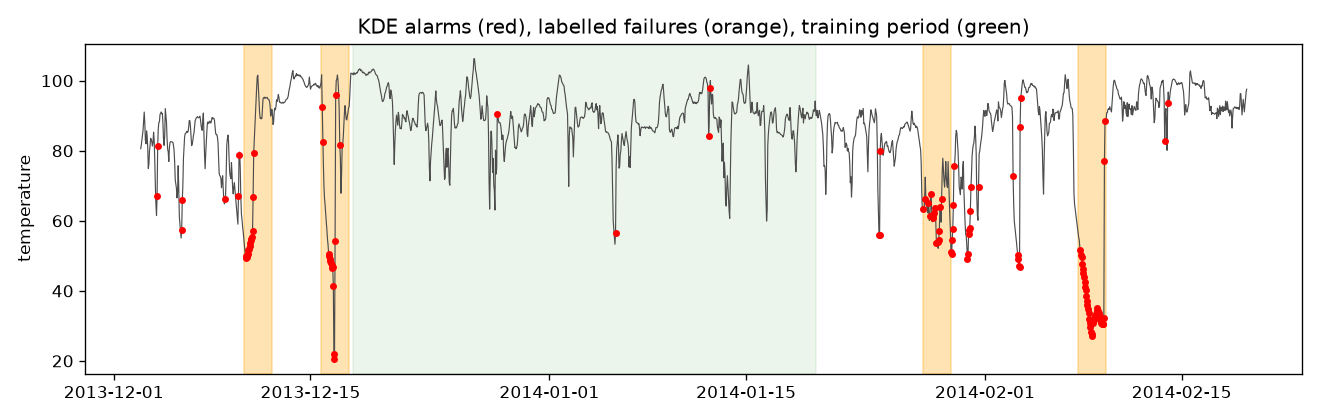

In [ ]:
from IPython.display import Image
Image('outputs/alarms.png')

The width chosen is `h = 0.5` (in standard deviations). Now compare the models:

- Both **Gaussians** find only 2 of the 4 failures. A Gaussian has one peak at the average, so it can only say "far
  from the average". During training the machine sometimes dropped to the low 50s and recovered, so a Gaussian must
  accept those temperatures, and the first and third failures stay in a similar range.
- The **KDE** finds all 4. It doesn't treat all low temperatures alike: it knows which combinations of temperature and
  change actually happened in normal weeks, and the failures produce combinations that didn't. The price is 0.9 false
  alarms per day.
- The full and independent Gaussians behave almost the same here, so the correlation between the two features carries
  little information for this task.

Look at the plot too. Several "false alarms" sit just before the labelled windows at the end of January. The labels are
someone's judgement of where a failure starts, and a detector that warns early may be doing its job. Real projects
always have this kind of fuzzy ground truth, and it's worth saying so in your README.

## Step 4: write the README and publish

In [ ]:
%%writefile README.md
# Machine failure detector

Detects failures of a large industrial machine from its temperature sensor, by learning what "normal" looks like with
density models in PyTorch and raising an alarm when an hour is too unlikely. Data: the Numenta Anomaly Benchmark
(11 weeks of readings every 5 minutes, with four failure periods labelled by engineers).

![alarms](outputs/alarms.png)

## Results

Models are fitted on 33 days of normal operation only. Threshold: the alarm level that 0.5% of normal hours reach.

| model | failures found | false alarms per day |
|---|---|---|
| Gaussian, independent features | 2 / 4 | 0.13 |
| Gaussian, full covariance | 2 / 4 | 0.16 |
| kernel density estimate (width chosen on held-out hours) | 4 / 4 | 0.90 |

A single Gaussian only knows "far from the average". The kernel density estimate follows the real shape of normal
behaviour and catches all four failures, at the cost of more false alarms.

## Run it

```bash
pip install -r requirements.txt
python detect.py
```

## What I learned

- Anomaly detection is density estimation: unusual means low probability under a model of normal data.
- Model choice matters more than tuning: a Gaussian's single peak missed half the failures.
- The alarm threshold is a trade-off between missed failures and false alarms, and must be set on normal data only.

Based on chapter 3 of *Deep Learning: Foundations and Concepts* (Bishop & Bishop, 2024).

Writing README.md


```bash
git add .
git commit -m "Density-based machine failure detector"
git branch -M main
git remote add origin git@github.com:YOUR-USERNAME/failure-detector.git
git push -u origin main
```

## Make it yours

- **Fewer false alarms.** Only raise an alarm when 2 or 3 hours in a row are flagged. How do the numbers change?
- **Nearest neighbours.** Add the K-nearest-neighbour density of section 3.5.3 as a fourth model.
- **A mixture of Gaussians.** Fit a mixture of 3 Gaussians (section 3.2.9). You'll learn the EM algorithm properly in
  part 4; for now, `sklearn.mixture.GaussianMixture` can fit it, and you only need its `score_samples` for log p(x).
  Does a few peaks do as well as a bump on every point?
- **Another sensor.** The benchmark has dozens of other streams (CPU usage, taxi demand, ambient temperature). Point
  `data.py` at another file from `realKnownCause/` and see if your detector still works.

## On your CV

> **Machine failure detector** (PyTorch): unsupervised anomaly detection on an industrial temperature sensor (Numenta
> Anomaly Benchmark) with Gaussian and kernel density models; caught 4/4 labelled failures at 0.9 false alarms per
> day, versus 2/4 for a Gaussian baseline. github.com/YOUR-USERNAME/failure-detector

## Check yourself

- [ ] The models never see the failure labels during fitting or threshold choice.
- [ ] You can explain why a single Gaussian missed two failures.
- [ ] You can explain the trade-off the 0.5% threshold controls.